In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
!pip install -U ultralytics roboflow


In [ ]:
!mkdir -p /content/drive/MyDrive/TrafficSignProject
%cd /content/drive/MyDrive/TrafficSignProject


In [ ]:
!pip install roboflow
from roboflow import Roboflow
rf = Roboflow(api_key="h0OHddZSk8yFBXwWcJ02")
project = rf.workspace("roboflow-100").project("road-signs-6ih4y")
version = project.version(2)
dataset = version.download("yolov5")

In [2]:
!pip install -U ultralytics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 75.4 MB/s eta 0:00:00


In [3]:
%cd /content/drive/MyDrive/TrafficSignProject


/content/drive/MyDrive/TrafficSignProject


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8s.pt")

model.train(
    data="road-signs-2/data.yaml",
    epochs=150,
    imgsz=640
)


In [ ]:
!cp runs/detect/train3/weights/best.pt /content/drive/MyDrive/TrafficSignProject/


In [ ]:
!yolo task=detect \
mode=predict \
model=/content/drive/MyDrive/TrafficSignProject/best.pt \
source=road-signs-2/test/images\
conf=0.25 \
save=True


In [ ]:
import os
from IPython.display import Image, display

pred_dir = "/content/drive/MyDrive/TrafficSignProject/runs/detect/predict46"

for file in os.listdir(pred_dir):
    if file.lower().endswith((".png", ".jpg", ".jpeg")):
        display(Image(filename=os.path.join(pred_dir, file)))



Output hidden; open in https://colab.research.google.com to view.

Saving Capture.PNG to Capture (3).PNG
Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.

image 1/1 /content/drive/MyDrive/TrafficSignProject/Capture (3).PNG: 640x640 2 do_not_enters, 2 do_not_stops, 1 do_not_u_turn, 1 enter_left_lane, 1 no_parking, 1 ped_crossing, 16.3ms
Speed: 78.2ms preprocess, 16.3ms inference, 40.7ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/TrafficSignProject/runs/detect/predict-2


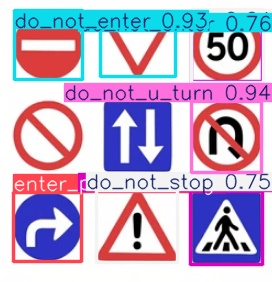

In [ ]:
# Step 1: Upload image
from google.colab import files
uploaded = files.upload()

# Get uploaded image name
image_path = list(uploaded.keys())[0]

# Step 2: Load YOLOv8 model
from ultralytics import YOLO
model = YOLO("/content/drive/MyDrive/TrafficSignProject/best.pt")

# Step 3: Predict
results = model.predict(
    source=image_path,
    conf=0.25,
    save=True
)

# Step 4: Display output image automatically
from IPython.display import Image, display
import os

# YOLO gives exact save directory
save_dir = results[0].save_dir

# YOLO saves output as .jpg
output_image = os.path.join(
    save_dir,
    os.path.splitext(os.path.basename(image_path))[0] + ".jpg"
)

display(Image(filename=output_image))


In [ ]:
import os

folders = {
    "Train": "road-signs-2/train/images",
    "Validation": "road-signs-2/valid/images",
    "Test": "road-signs-2/test/images"
}

for name, path in folders.items():
    print(name, "images:", len(os.listdir(path)))


Train images: 1376
Validation images: 488
Test images: 229


In [ ]:
from google.colab import files
uploaded = files.upload()
video_path = list(uploaded.keys())[0]
print("Uploaded video:", video_path)

from ultralytics import YOLO
model = YOLO("/content/drive/MyDrive/TrafficSignProject/best.pt")

results = model.predict(
    source=video_path,
    conf=0.25,
    save=True,
    project="/content/runs",
    name="video_detect"
)

print("Detection completed")

import os

save_dir = results[0].save_dir
print("YOLO output folder:", save_dir)

output_video = None
for f in os.listdir(save_dir):
    if f.lower().endswith((".avi", ".mp4", ".mov")):
        output_video = os.path.join(save_dir, f)
        break

if output_video is None:
    raise FileNotFoundError("Output video not found")

print("Detected output video:", output_video)

final_video = output_video

if output_video.lower().endswith(".avi"):
    final_video = save_dir + "/final_output.mp4"
    !ffmpeg -y -i "$output_video" -vcodec libx264 -acodec aac "$final_video"
    print("Converted to MP4:", final_video)
else:
    print("Video already in MP4 format")

from IPython.display import Video, display

display(
    Video(
        final_video,
        embed=True,
        width=640,
        height=360
    )
)